# Pebas Formation — Tamshiyacu (TAM) & Santa Carina (SC) stratigraphic columns
Lithostratigraphic columns built with **pystrat** from the field-log workbook
`Pebas_Lithology_Anderson.xlsx` (sheets *Tamshiyacu TAM*, *Santa Carina SC*),
in the same style as the Madre de Dios SDAR fence notebook.

Each column shows: FGDC lithofacies swatch + grain-size width profile, the
**paleomagnetic cored interval**, geochem/paleomag **sample positions**, the
***Purussaurus* cranial horizon** (TAM), and key marker beds (lignites, mollusc
beds, concretions). A **TAM↔SC fence** is drawn at the end.

**Editable layers:** everything interpretive lives in two places you can change and
re-run — the `FACIES` style table (§1) and the `TAM_BEDS` / `SC_BEDS` tables (§3).
The sample heights in §2 are computed straight from the workbook.

> **Assumptions flagged for review** (see §2–§3):
> 1. TAM was logged **downward** from the top (0) in two cm-series (TAM 1–13, then
>    TAM 17–29 after a covered interval); heights are converted to *height above base*.
> 2. The TAM sheet note *"Paleomag … core starts/ends here"* (written "SC" on the
>    sheet) is taken as the **TAM** paleomag section: TAM 17 → TAM 29 = 0.00–2.06 m.
> 3. *Purussaurus* is at **TAM 13 (112 cm) = 2.44 m above base**, ~0.4 m above the
>    top of the cored interval.
> 4. Bed boundaries between described samples are interpolated from the metre ties.

## 0 · Setup
Run once to install pystrat if needed, then imports. Put this notebook in the same
folder as `Pebas_Lithology_Anderson.xlsx` (the `stratigraphy/` folder of the repo).

In [1]:
# %pip install pystrat openpyxl pandas matplotlib
import os, re, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Wedge, Ellipse, FancyBboxPatch, ConnectionPatch, Patch
from matplotlib.lines import Line2D
import pystrat
warnings.filterwarnings("ignore")

# locate the workbook next to this notebook (edit if needed)
CANDIDATES = ["Pebas_Lithology_Anderson.xlsx",
              os.path.join(os.getcwd(), "Pebas_Lithology_Anderson.xlsx"),
              os.path.join(os.getcwd(), "stratigraphy", "Pebas_Lithology_Anderson.xlsx")]
XLSX = next((p for p in CANDIDATES if os.path.isfile(p)), CANDIDATES[0])
OUT  = "figs"; os.makedirs(OUT, exist_ok=True)
print("workbook:", XLSX, "| exists:", os.path.isfile(XLSX))
print("pystrat", pystrat.__version__)

workbook: Pebas_Lithology_Anderson.xlsx | exists: True
pystrat 2.4.1


## 1 · Facies scheme (colours, grain-size width, FGDC swatch)
`width` (0–1) is the pystrat grain-size profile (fine→narrow, coarse→wide). `swatch`
is an FGDC/USGS code bundled with pystrat (0 = solid colour fill). Edit freely.

In [2]:
FACIES = pd.DataFrame([
    # label                  color       width  swatch  fcode (Gingras et al. 2002, Table 1)
    ("lignite/coal",        "#242424",  0.24,   0,   "F3A"),
    ("organic clay",        "#5c5138",  0.32,   0,   "F1B"),
    ("mudstone (clay)",     "#8fb0c0",  0.40,   616, "F1A/B"),  # 616 = shale/mud dashes
    ("silty clay",          "#a9c3d1",  0.52,   613, "F2C/D"),  # 613 = siltstone
    ("sandy clay",          "#cbb48f",  0.66,   607, "F2A/B"),  # 607 = sandstone
    ("shell bed",           "#e9d9a6",  0.58,   627, "F3B"),    # 627 = shelly/limestone
    ("covered / no exposure","#efefef", 0.12,   0,   ""),
], columns=["label","color","width","swatch","fcode"])

STYLE = pystrat.Style(FACIES.label.tolist(), FACIES.color.tolist(),
                      FACIES.width.tolist(), swatch_values=FACIES.swatch.tolist())
def leglabel(r): return f"{r.label} ({r.fcode})" if r.fcode else r.label

# marker colours
C_PMAG="#c0392b"; C_PURU="#8e44ad"; C_SHELL="#7d6608"; C_CONC="#5d6d7e"; C_SAMP="#34495e"
FACIES

,label,color,width,swatch,fcode
0,lignite/coal,#242424,0.24,0,F3A
1,organic clay,#5c5138,0.32,0,F1B
2,mudstone (clay),#8fb0c0,0.40,616,F1A/B
3,silty clay,#a9c3d1,0.52,613,F2C/D
4,sandy clay,#cbb48f,0.66,607,F2A/B
5,shell bed,#e9d9a6,0.58,627,F3B
6,covered / no exposure,#efefef,0.12,0,


## 2 · Read the field logs → sample heights
TAM is logged **down from the top** in two cm-series with a covered gap; SC is logged
**up from the base** (0–5 m). Heights below are *metres above each section's base* and
are computed directly from the sheet so you can check them against the workbook.

In [3]:
def _cm(s):
    m=re.search(r"\(([\d.]+)\s*cm", str(s)); return float(m.group(1)) if m else None

# ---------- TAM ----------
tam = pd.ExcelFile(XLSX).parse("Tamshiyacu TAM", header=None)
# Height model (base=0 at TAM 29, top~3.78 m): two field cm-series separated by a ~60 cm gap.
#  series-2 (TAM 17-29, lower): TAM 17 (2 cm) at 2.06 m -> TAM 29 (208 cm) at 0 m.
#  series-1 (TAM 1-13, upper) sits above the 60 cm gap: TAM 13 (112 cm) at 2.66 m -> up to surface.
rows=[]
for r in range(2, tam.shape[0]):
    samp=tam.iat[r,2]; cm=_cm(samp)
    if cm is None: continue
    n=int(re.search(r"TAM\s*0*(\d+)", str(samp)).group(1))
    h = 2.66 + (112 - cm)/100.0 if n<=13 else 2.06 - (cm - 2)/100.0
    rows.append(dict(sample=f"TAM {n}", height=round(h,3),
                     detail=str(tam.iat[r,4]) if not pd.isna(tam.iat[r,4]) else "",
                     litho=str(tam.iat[r,3]) if not pd.isna(tam.iat[r,3]) else "",
                     pmag=str(tam.iat[r,5]) if not pd.isna(tam.iat[r,5]) else ""))
TAM_SAMP=pd.DataFrame(rows).sort_values("height").reset_index(drop=True)

# ---------- SC ----------
sc = pd.ExcelFile(XLSX).parse("Santa Carina SC", header=None)
# row->metre ties (metre column increases downward-in-sheet = upward in section)
ties={r:float(str(sc.iat[r,0]).replace("m","")) for r in range(sc.shape[0])
      if not pd.isna(sc.iat[r,0]) and str(sc.iat[r,0]).replace("m","").replace(".","",1).lstrip("-").isdigit()}
tr=sorted(ties);
def sc_h(r):  # interpolate a row index to metres from the tie rows
    if r<=tr[0]: return ties[tr[0]]
    if r>=tr[-1]: return ties[tr[-1]]
    a=max(t for t in tr if t<=r); b=min(t for t in tr if t>=r)
    return ties[a]+(ties[b]-ties[a])*((r-a)/(b-a)) if b!=a else ties[a]
rows=[]
for r in range(1, sc.shape[0]):
    samp=sc.iat[r,2]
    if pd.isna(samp) or not str(samp).strip().lower().startswith("pebas"): continue
    rows.append(dict(sample=str(samp).strip(), height=round(sc_h(r),3),
                     litho=str(sc.iat[r,3]) if not pd.isna(sc.iat[r,3]) else "",
                     pmag=str(sc.iat[r,5]) if not pd.isna(sc.iat[r,5]) else ""))
SC_SAMP=pd.DataFrame(rows).sort_values("height").reset_index(drop=True)

print("TAM samples:", len(TAM_SAMP), "| SC samples:", len(SC_SAMP))
print("\nTAM (height m above base):"); print(TAM_SAMP[["sample","height","detail"]].to_string(index=False))
print("\nSC (height m above base):");  print(SC_SAMP[["sample","height","litho"]].head(30).to_string(index=False))

TAM samples: 26 | SC samples: 25

TAM (height m above base):
sample  height                               detail
TAM 29    0.00                                     
TAM 28    0.20                        mollusc layer
TAM 27    0.23                        lower lignite
TAM 26    0.33                        mollusc layer
TAM 25    0.48                              missing
TAM 24    0.68                                     
TAM 23    0.88                                     
TAM 22    1.08                                     
TAM 21    1.28                                     
TAM 20    1.48                                     
TAM 19    1.68                                     
TAM 18    1.88                                     
TAM 17    2.06                   2 cm mollusc layer
TAM 13    2.66 Purussaurus craneal part found here!
TAM 12    2.76                                     
TAM 11    2.86                                     
TAM 10    2.95                                     
 TA

## 3 · Beds & markers (interpretive — edit here)
The bed tables translate the sample lithologies into continuous facies intervals
(bottom→top, metres). Marker dictionaries hold the paleomag cored interval,
*Purussaurus*, mollusc beds, concretions and key surfaces. **This is the layer to edit.**

In [4]:
# base_m, top_m, facies   (total ~3.78 m, matching the OSU core-length composite 3.84 m).
#  Registration by u-channel core lengths: Group 3 (base) 0-1.13 m and Group 2 (mid) 1.13-2.54 m
#  carry polarity; Group 1 (top, 2.54-3.78 m; TAM_1_2_3B) is NRM-only / poor-chi = NO polarity data
#  and hosts the Purussaurus-bearing lignite. Former "covered" interval now logged as bgc.
TAM_BEDS = pd.DataFrame([
    (0.00, 0.20, "mudstone (clay)"),        # light grey clay w/ mollusc (TAM 28-29)      [G3]
    (0.20, 0.26, "lignite/coal"),           # lower lignite (TAM 27)                        [G3]
    (0.26, 2.06, "silty clay"),             # light grey clay, sand+OM laminae (TAM 17-26)  [G3->G2]
    (2.06, 2.66, "mudstone (clay)"),        # blue-grey clay (former covered gap, now bgc)  [G2]
    (2.66, 2.76, "lignite/coal"),           # lignite hosting the Purussaurus cranial       [G1 base]
    (2.76, 3.40, "mudstone (clay)"),        # blue-grey clay (TAM 7-12)                     [G1]
    (3.40, 3.60, "organic clay"),           # brown clay, mass-flow, carbonaceous (TAM 3-6) [G1]
    (3.60, 3.78, "lignite/coal"),           # upper lignite (TAM 2)                          [G1 top]
], columns=["base_m","top_m","facies"])

SC_BEDS = pd.DataFrame([
    (0.00, 0.45, "mudstone (clay)"),   # dark grey clay, mollusc + ostracod bed
    (0.45, 0.65, "lignite/coal"),      # lignite/organic clay w/ mollusc beds (Pebas 17)
    (0.65, 0.90, "organic clay"),      # organic clay with burrows (Pebas 20)
    (0.90, 1.80, "sandy clay"),        # sandy vf blue clay, parallel lam; white mottles
    (1.80, 2.50, "mudstone (clay)"),   # blue-grey clay w/ molluscs (+OM)
    (2.50, 4.90, "silty clay"),        # blue-grey silty clay, occasionally molluscs
    (4.90, 5.00, "lignite/coal"),      # coal lenses in clayey sand, blue mottles (Pebas 38)
], columns=["base_m","top_m","facies"])

MARKERS = {
 "TAM": dict(
    pmag=(0.00, 2.54),                 # polarity data = Groups 3+2 (core lengths 1.13+1.41 m)
    nodata_top=(2.54, 3.78),           # Group 1 (TAM_1_2_3B): NRM-only / poor-chi = NO polarity data
    purussaurus=2.71,                  # TAM 13 cranial, in the Group-1 lignite (no polarity here)
    molluscs=[0.20, 0.33, 2.06],       # TAM 28, TAM 26, TAM 17 (2 cm mollusc)
    concretions=[], erosive=[], covered=[],
    surfaces=[(0.23,"FS (lignite)"),(0.30,"TSE"),(3.69,"FS (lignite)")],
    parasequences=[(0.30,3.69,"PS")],
    key_samples={"TAM 2":"upper lignite","TAM 13":"Purussaurus",
                 "TAM 27":"lower lignite","TAM 29":"pmag base"}),
 "SC": dict(
    pmag=(1.60, 5.00),                 # Pebas 38 (top) -> 20 cm below concretion 4 (field note)
    purussaurus=None,
    molluscs=[0.30, 0.60, 1.90, 2.30], concretions=[1.80, 2.00, 2.60, 4.20],
    erosive=[], covered=[],
    surfaces=[(0.55,"FS (lignite)"),(0.65,"TSE"),(4.95,"FS (lignite)")],
    parasequences=[(0.65,4.90,"PS")],
    key_samples={"Pebas 38":"pmag top / lignite","Pebas 17":"lignite","Pebas 14":"base"}),
}
print(TAM_BEDS, "\n\n", SC_BEDS)

   base_m  top_m           facies
0    0.00   0.20  mudstone (clay)
1    0.20   0.26     lignite/coal
2    0.26   2.06       silty clay
3    2.06   2.66  mudstone (clay)
4    2.66   2.76     lignite/coal
5    2.76   3.40  mudstone (clay)
6    3.40   3.60     organic clay
7    3.60   3.78     lignite/coal 

    base_m  top_m           facies
0    0.00   0.45  mudstone (clay)
1    0.45   0.65     lignite/coal
2    0.65   0.90     organic clay
3    0.90   1.80       sandy clay
4    1.80   2.50  mudstone (clay)
5    2.50   4.90       silty clay
6    4.90   5.00     lignite/coal


## 4 · Magnetostratigraphy — polarity zones (from the OSU u-channel synthesis)
Polarity zones from `polarity_synthesis/polarity_zones.csv` (composite cm). They are drawn
as a thin track beside each column, scaled into that section's paleomag cored interval
(**registration schematic** — composite depth vs field metres is only approximate). The
tie of the SC reversed zone to **C5AAr** (~13.18–13.36 Ma) is the correlation anchor.

In [5]:
# polarity zones (site, top_cm, bottom_cm, polarity); read from repo, else embedded fallback
_pz=None
for p in ["../polarity_synthesis/polarity_zones.csv","polarity_synthesis/polarity_zones.csv"]:
    if os.path.isfile(p): _pz=pd.read_csv(p); break
if _pz is None:
    _pz=pd.DataFrame([("TAM",0,50,"R"),("TAM",51,72,"N"),("TAM",78,99,"N"),
        ("SC",0,103,"N"),("SC",106,149,"R"),("SC",150,173,"N"),("SC",179,227,"N"),("SC",245,262,"N")],
        columns=["site","top_cm","bottom_cm","polarity"])
POL_ZONES={s:d[["top_cm","bottom_cm","polarity"]].values.tolist() for s,d in _pz.groupby("site")}
# chron labels to annotate (edit as the correlation is refined)
CHRON={"SC":{"C5AAr":(106,149)}}   # SC reversed zone = C5AAr
print(POL_ZONES)

{'SC': [[0, 103, 'N'], [106, 149, 'R'], [150, 173, 'N'], [179, 227, 'N'], [245, 262, 'N']], 'TAM': [[0, 50, 'R'], [51, 72, 'N'], [78, 99, 'N']]}


## 5 · Plot helper — pystrat column + overlays + polarity track

In [6]:
def build_section(beds, name):
    th=(beds.top_m-beds.base_m).tolist()
    return pystrat.Section(th, beds.facies.tolist(), name=name)

def _shell(ax,x,h,s=0.045): ax.add_patch(Wedge((x,h),s,200,340,facecolor=C_SHELL,ec="k",lw=.4,zorder=6))
def _conc(ax,x,h,s=0.05):  ax.add_patch(Ellipse((x,h),s*1.7,s*1.0,facecolor=C_CONC,ec="k",lw=.4,zorder=6))
def _wavy(ax,h,x0=0,x1=1):
    xs=np.linspace(x0,x1,120); ax.plot(xs,h+0.015*np.sin(xs*40),color="k",lw=1.0,zorder=6)

C_NODATA="#d9d9d9"
def _nodata(ax,x0,x1,y0,y1,z=5):
    ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,facecolor=C_NODATA,ec="k",lw=0.5,hatch="xxx",zorder=z))

def draw_polarity(ax, site, pmag, section_top=None, beds=None, no_pol=None, x0=1.15, x1=1.34):
    """Polarity column beside the litho log. The whole section (0..section_top) is drawn as
    hatched 'no data'; measured N/R zones are overlaid only within the data interval `pmag`.
    Additional no-data is punched over lignite/coal beds (organic, poor recorder) and any
    explicit `no_pol` ranges (e.g. an unrecoverable core such as TAM Group 1)."""
    zones=POL_ZONES.get(site,[])
    if not zones: return
    lo=min(z[0] for z in zones); hi=max(z[1] for z in zones); span=hi-lo
    a,b=pmag                                    # data (cored) interval, field metres
    top=section_top if section_top is not None else b
    def toH(cm): return b-(cm-lo)/span*(b-a)    # composite top(lo)->field top(b)
    _nodata(ax,x0,x1,0,top,z=3)                 # background = NO data across the whole section
    for t,bt,pol in zones:                      # overlay measured N/R zones (data interval only)
        y0,y1=sorted((toH(t),toH(bt)))
        ax.add_patch(Rectangle((x0,y0),x1-x0,y1-y0,
                     facecolor=("k" if pol=="N" else "w"),ec="k",lw=0.5,zorder=4))
    # punch out no-data over lignites + explicit no_pol ranges
    gaps=list(no_pol or [])
    if beds is not None:
        for _,r in beds.iterrows():
            if "lignite" in str(r.facies): gaps.append((r.base_m,r.top_m))
    for g0,g1 in gaps:
        y0,y1=max(0,min(g0,g1)),min(top,max(g0,g1))
        if y1>y0: _nodata(ax,x0,x1,y0,y1,z=6)
    ax.text((x0+x1)/2, top+0.03*top+0.02, "pol.", ha="center", fontsize=6.5)
    for name,(ct,cb) in CHRON.get(site,{}).items():
        yc=(toH(ct)+toH(cb))/2
        ax.annotate(name,(x1,yc),xytext=(x1+0.04,yc),fontsize=6.5,color=C_PMAG,va="center",weight="bold")

def plot_column(beds, samp, mk, name, ax=None, save=None, sample_ticks=True,
                polarity=False, site=None, lab_x=None):
    sec=build_section(beds,name); tot=beds.top_m.max()
    if ax is None: fig,ax=plt.subplots(figsize=(3.6,0.9+tot*1.2))
    else: fig=ax.figure
    sec.plot(STYLE, ax=ax)
    xr = 1.95 if polarity else 1.45
    ax.set_ylim(-0.05*tot, tot*1.08); ax.set_xlim(-0.34, xr)
    ax.set_ylabel("Height above base (m)"); ax.set_title(name, weight="bold")
    ax.set_yticks(np.arange(0, tot+0.01, 0.5))
    ax.set_xticks([]); ax.grid(False)
    for sp in ("top","right","bottom"): ax.spines[sp].set_visible(False)
    lab_x = lab_x if lab_x is not None else (1.42 if polarity else 1.06)
    # covered / missing sections (hatched band + label)
    for a,b in mk.get("covered",[]):
        ax.add_patch(Rectangle((0,a),1,b-a,facecolor="w",ec="k",lw=0.8,hatch="////",zorder=3))
        ax.text(0.5,(a+b)/2,f"covered\n~{round((b-a)*100)} cm",ha="center",va="center",fontsize=6.5,style="italic")
    # paleomag cored interval (left bracket)
    if mk.get("pmag"):
        a,b=mk["pmag"]; xb=-0.30
        ax.plot([xb,xb],[a,b],color=C_PMAG,lw=3,solid_capstyle="butt",zorder=5)
        for y in (a,b): ax.plot([xb,xb+0.05],[y,y],color=C_PMAG,lw=2)
        ax.text(xb-0.03,(a+b)/2,"paleomag\ncored",color=C_PMAG,rotation=90,
                va="center",ha="right",fontsize=7,weight="bold")
    # polarity track
    if polarity and site and mk.get("pmag"):
        draw_polarity(ax, site, mk["pmag"], section_top=beds.top_m.max(), beds=beds,
                      no_pol=(mk.get("no_pol") or []) + ([mk["nodata_top"]] if mk.get("nodata_top") else []))
    # sample ticks + key labels (to the right)
    if sample_ticks:
        for _,s in samp.iterrows():
            ax.plot([-0.02,0.0],[s.height,s.height],color=C_SAMP,lw=0.6,zorder=4)
        for lab,txt in mk.get("key_samples",{}).items():
            row=samp[samp["sample"]==lab]
            if len(row):
                h=float(row.height.iloc[0])
                ax.annotate(f"{lab} · {txt}",(lab_x,h),ha="left",va="center",fontsize=6.2,color=C_SAMP)
    # markers
    for h in mk.get("molluscs",[]): _shell(ax,0.9,h)
    for h in mk.get("concretions",[]): _conc(ax,0.78,h)
    for h in mk.get("erosive",[]): _wavy(ax,h)
    if mk.get("purussaurus") is not None:
        h=mk["purussaurus"]; ax.plot(0.5,h,marker=(5,1,0),ms=17,mfc=C_PURU,mec="k",mew=.8,zorder=8)
        ax.annotate("Purussaurus\ncranial",(0.5,h),xytext=(0.60,h),fontsize=7,color=C_PURU,va="center")
    # key surfaces: FS (flooding surface, green) / TSE / Glossifungites (brown) as horizontal lines
    for h,lab in mk.get("surfaces",[]):
        c = "#1a7a3a" if lab.upper().startswith("FS") else "#7b3f00"
        ax.plot([0,1.0],[h,h],color=c,lw=1.2,ls=(0,(4,2)),zorder=6)
        ax.text(1.0,h,f" {lab}",ha="left",va="center",fontsize=5.6,color=c)
    # parasequence brackets (right side)
    for a,b,lab in mk.get("parasequences",[]):
        xb=1.05
        ax.plot([xb,xb],[a,b],color="0.25",lw=2,zorder=5)
        for y in (a,b): ax.plot([xb-0.04,xb],[y,y],color="0.25",lw=1.5)
        ax.text(xb+0.03,(a+b)/2,lab,rotation=90,va="center",ha="left",fontsize=7,weight="bold",color="0.25")
    if save: fig.savefig(save+".png",dpi=220,bbox_inches="tight"); fig.savefig(save+".svg",bbox_inches="tight")
    return fig,ax

## 6 · Single columns (with polarity track)

saved fig_strat_TAM.png/.svg


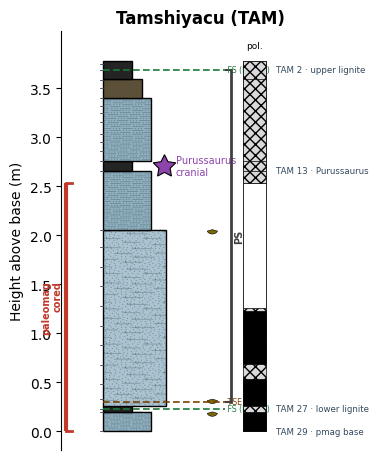

In [7]:
figT,_=plot_column(TAM_BEDS, TAM_SAMP, MARKERS["TAM"], "Tamshiyacu (TAM)",
                   polarity=True, site="TAM", save=os.path.join(OUT,"fig_strat_TAM"))
print("saved fig_strat_TAM.png/.svg")

saved fig_strat_SC.png/.svg


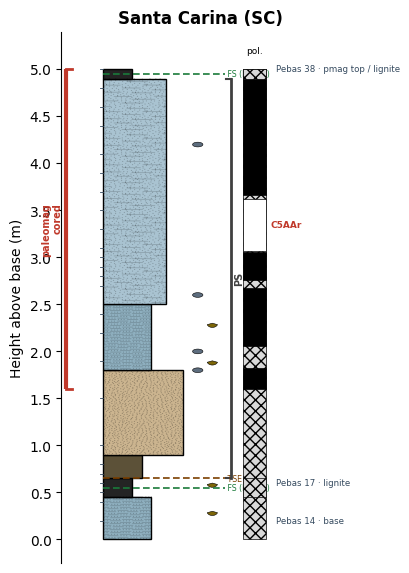

In [8]:
figS,_=plot_column(SC_BEDS, SC_SAMP, MARKERS["SC"], "Santa Carina (SC)",
                   polarity=True, site="SC", save=os.path.join(OUT,"fig_strat_SC"))
print("saved fig_strat_SC.png/.svg")

## 7 · Fence (TAM ↔ SC) with polarity, hung on section base
Both columns share a height axis with their polarity tracks. No bed-to-bed tie is forced
(the real correlation is magnetostratigraphy → GPTS; SC reversed zone = C5AAr). The
paleomag cored interval is shaded on each. Set `DATUMS` to align on a marker instead.

saved fig_fence_TAM_SC.png/.svg


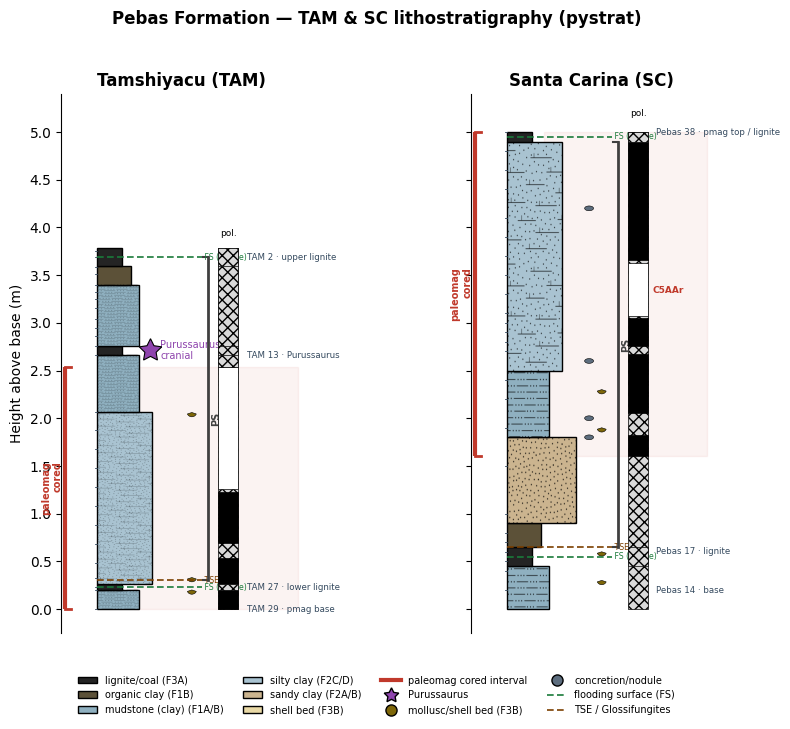

In [9]:
def plot_fence(save=None):
    fig,axes=plt.subplots(1,2,figsize=(8.4, 1.0+max(TAM_BEDS.top_m.max(),SC_BEDS.top_m.max())*1.2),
                          sharey=True, gridspec_kw=dict(wspace=0.7))
    plot_column(TAM_BEDS, TAM_SAMP, MARKERS["TAM"], "Tamshiyacu (TAM)", ax=axes[0], polarity=True, site="TAM")
    plot_column(SC_BEDS,  SC_SAMP,  MARKERS["SC"],  "Santa Carina (SC)", ax=axes[1], polarity=True, site="SC")
    axes[1].set_ylabel("")
    # shade paleomag intervals
    for ax,site in zip(axes,("TAM","SC")):
        a,b=MARKERS[site]["pmag"]; ax.axhspan(a,b,xmin=0.30,xmax=0.98,color=C_PMAG,alpha=0.06,zorder=0)
    # legend
    from matplotlib.patches import Patch
    leg=[Patch(fc=r.color,ec="k",label=leglabel(r)) for _,r in FACIES.iterrows() if r.label!="covered / no exposure"]
    leg+=[Line2D([0],[0],color=C_PMAG,lw=3,label="paleomag cored interval"),
          Line2D([0],[0],marker=(5,1,0),color="w",mfc=C_PURU,mec="k",ms=11,label="Purussaurus"),
          Line2D([0],[0],marker="o",color="w",mfc=C_SHELL,mec="k",ms=8,label="mollusc/shell bed (F3B)"),
          Line2D([0],[0],marker="o",color="w",mfc=C_CONC,mec="k",ms=8,label="concretion/nodule"),
          Line2D([0],[0],color="#1a7a3a",lw=1.2,ls=(0,(4,2)),label="flooding surface (FS)"),
          Line2D([0],[0],color="#7b3f00",lw=1.2,ls=(0,(4,2)),label="TSE / Glossifungites")]
    fig.legend(handles=leg,loc="lower center",ncol=4,fontsize=7,frameon=False,bbox_to_anchor=(0.5,-0.02))
    fig.suptitle("Pebas Formation — TAM & SC lithostratigraphy (pystrat)", y=1.0, fontsize=12, weight="bold")
    if save: fig.savefig(save+".png",dpi=220,bbox_inches="tight"); fig.savefig(save+".svg",bbox_inches="tight")
    return fig
plot_fence(save=os.path.join(OUT,"fig_fence_TAM_SC"))
print("saved fig_fence_TAM_SC.png/.svg")

## 7b · Magnetostratigraphic fence — aligned on the reversal (shared chrons)
The two sections are hung on the **N→R reversal** (SC's reversed zone = **C5AAr**), so the
magnetostratigraphy is **horizontal**. With the reversals aligned, both sections show **Normal
below → Reversed at the datum**: they share the same chron boundary (C5AAn→C5AAr). Note that the
lignites no longer line up — they are **diachronous** facies boundaries, which is why a lignite tie
(previous version) forced the polarity out of agreement. Time correlation follows the reversal.

saved fig_fence_genetic.png/.svg


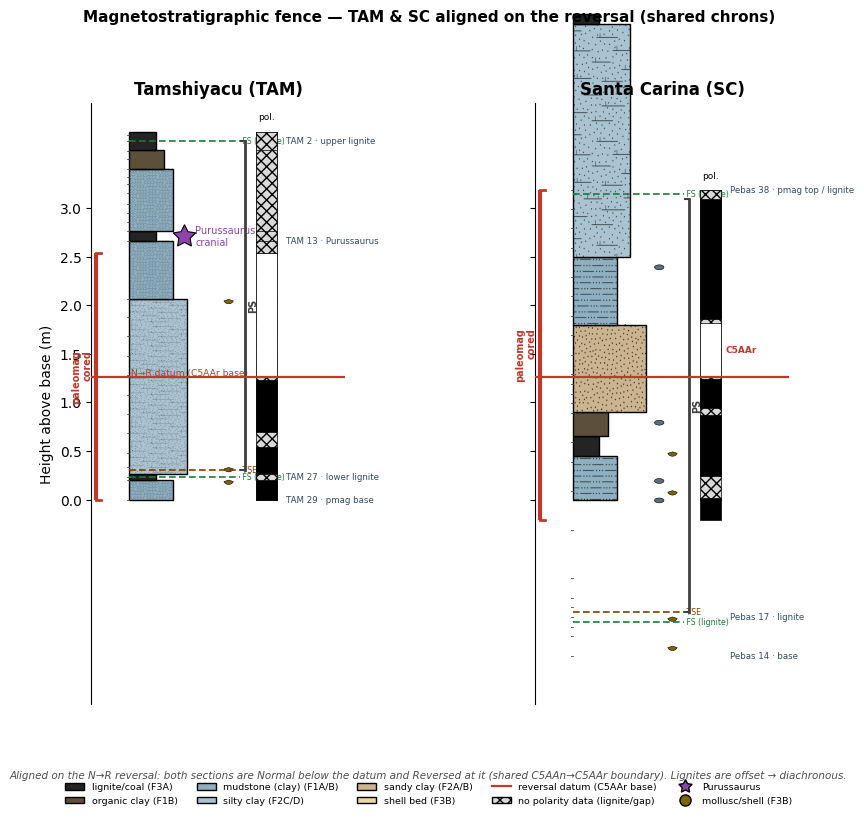

In [10]:
def _rev_base(site,pmag):
    """field height of the N->R boundary (base of the reversed interval) for a site."""
    z=POL_ZONES[site]; lo=min(x[0] for x in z); hi=max(x[1] for x in z); a,b=pmag
    cm=max(x[1] for x in z if x[2]=="R")          # deepest base of the reversed zone (composite cm)
    return b-(cm-lo)/(hi-lo)*(b-a)

def genetic_fence(save=None):
    tam_pmag=MARKERS["TAM"]["pmag"]; sc_pmag=MARKERS["SC"]["pmag"]
    datum=_rev_base("TAM",tam_pmag)               # align both N->R boundaries to TAM's
    offSC=datum-_rev_base("SC",sc_pmag)           # vertical shift applied to the whole SC column
    sB=SC_BEDS.copy(); sB["base_m"]+=offSC; sB["top_m"]+=offSC
    sS=SC_SAMP.copy(); sS["height"]+=offSC
    sM=dict(MARKERS["SC"]); a,b=sM["pmag"]; sM["pmag"]=(a+offSC,b+offSC)
    for k in ("molluscs","concretions"): sM[k]=[h+offSC for h in MARKERS["SC"].get(k,[])]
    sM["surfaces"]=[(h+offSC,l) for h,l in MARKERS["SC"]["surfaces"]]
    sM["parasequences"]=[(x+offSC,y+offSC,l) for x,y,l in MARKERS["SC"]["parasequences"]]
    ymax=max(TAM_BEDS.top_m.max(), sB.top_m.max())+0.3; ymin=min(0,sB.base_m.min())-0.3
    fig,ax=plt.subplots(1,2,figsize=(9.0,1.0+(ymax-ymin)*1.1),sharey=True,gridspec_kw=dict(wspace=0.75))
    plot_column(TAM_BEDS,TAM_SAMP,MARKERS["TAM"],"Tamshiyacu (TAM)",ax=ax[0],polarity=True,site="TAM")
    plot_column(sB,sS,sM,"Santa Carina (SC)",ax=ax[1],polarity=True,site="SC")
    for a_ in ax: a_.set_ylim(ymin,ymax)
    ax[1].set_ylabel("")
    # horizontal magnetostratigraphic datum at the shared N->R (C5AAr base) boundary
    for a_ in ax: a_.axhline(datum,color=C_PMAG,lw=1.6,zorder=9)
    ax[0].text(0.02,datum,"N→R datum (C5AAr base)",fontsize=6.6,color=C_PMAG,va="bottom",ha="left")
    leg=[Patch(fc=r.color,ec="k",label=leglabel(r)) for _,r in FACIES.iterrows() if r.label!="covered / no exposure"]
    leg+=[Line2D([0],[0],color=C_PMAG,lw=1.6,label="reversal datum (C5AAr base)"),
          Patch(fc=C_NODATA,ec="k",hatch="xxx",label="no polarity data (lignite/gap)"),
          Line2D([0],[0],marker=(5,1,0),color="w",mfc=C_PURU,mec="k",ms=10,label="Purussaurus"),
          Line2D([0],[0],marker="o",color="w",mfc=C_SHELL,mec="k",ms=8,label="mollusc/shell (F3B)")]
    fig.legend(handles=leg,loc="lower center",ncol=5,fontsize=6.8,frameon=False,bbox_to_anchor=(0.5,-0.03))
    fig.text(0.5,0.015,"Aligned on the N→R reversal: both sections are Normal below the datum and Reversed at it "
             "(shared C5AAn→C5AAr boundary). Lignites are offset → diachronous.",
             ha="center",fontsize=7.5,style="italic",color="0.3")
    fig.suptitle("Magnetostratigraphic fence — TAM & SC aligned on the reversal (shared chrons)",
                 fontsize=11,weight="bold",y=1.0)
    if save: fig.savefig(save+".png",dpi=220,bbox_inches="tight"); fig.savefig(save+".svg",bbox_inches="tight")
    return fig
genetic_fence(save=os.path.join(OUT,"fig_fence_genetic"))
print("saved fig_fence_genetic.png/.svg")

## 8 · Published sections (Gingras et al. 2002, JSR 72:871–883) — digitized
Measured logs at **Tamshiyacu** (their Fig. 2/4; 2 parasequences TmA 0.82–3.08 m, TmB
3.08–6.40 m) and **Santa Julia II** (Fig. 2/3; SJA 0–3.25, SJB 3.25–6.95, SJC 6.95–~10 m).
Digitized **approximately** from Fig. 2 + the text; facies F1A/F1B→mudstone, F2A/F2B→sandy,
F2C/F2D→silty, F3A→lignite, F3B→shell bed, F3C→Glossifungites/TSE surface. Edit freely.

In [11]:
GT_BEDS = pd.DataFrame([   # Gingras Tamshiyacu (base_m, top_m, facies)
    (0.60,0.82,"lignite/coal"),(0.82,1.25,"mudstone (clay)"),(1.25,1.57,"silty clay"),
    (1.57,1.65,"sandy clay"),(1.65,2.10,"sandy clay"),(2.10,3.08,"mudstone (clay)"),
    (3.08,3.30,"lignite/coal"),(3.30,3.42,"shell bed"),(3.42,3.55,"mudstone (clay)"),
    (3.55,4.10,"silty clay"),(4.10,6.10,"sandy clay"),(6.10,6.40,"mudstone (clay)"),
], columns=["base_m","top_m","facies"])
GT_MK = dict(pmag=None, purussaurus=None, molluscs=[3.36], concretions=[2.12], erosive=[],
             covered=[], key_samples={}, surfaces=[(0.82,"TSE"),(3.08,"TSE")],
             parasequences=[(0.82,3.08,"TmA"),(3.08,6.40,"TmB")])

GSJ_BEDS = pd.DataFrame([  # Gingras Santa Julia II
    (0.00,0.15,"shell bed"),(0.15,0.52,"mudstone (clay)"),(0.52,1.30,"sandy clay"),
    (1.30,2.50,"sandy clay"),(2.50,3.10,"mudstone (clay)"),(3.10,3.25,"lignite/coal"),
    (3.25,4.20,"mudstone (clay)"),(4.20,5.80,"mudstone (clay)"),(5.80,6.95,"mudstone (clay)"),
    (6.95,7.40,"sandy clay"),(7.40,10.0,"mudstone (clay)"),
], columns=["base_m","top_m","facies"])
GSJ_MK = dict(pmag=None, purussaurus=None, molluscs=[0.08,3.45,4.60], concretions=[], erosive=[],
              covered=[], key_samples={}, surfaces=[(3.25,"TSE"),(6.95,"TSE")],
              parasequences=[(0.0,3.25,"SJA"),(3.25,6.95,"SJB"),(6.95,10.0,"SJC")])
_empty=pd.DataFrame(columns=["sample","height"])
print("Gingras Tamshiyacu:",GT_BEDS.top_m.max(),"m | Santa Julia:",GSJ_BEDS.top_m.max(),"m")

Gingras Tamshiyacu: 6.4 m | Santa Julia: 10.0 m


## 9 · Comparison — our columns vs the digitized Gingras sections
Each pair is aligned on the **lower lignite** (per the correlation choice): the Gingras
column is shifted so its lowest lignite sits at the height of our lower lignite (blue tie).
A second tie (dashed) is drawn to a candidate upper marker so you can see whether the rest
of the section stays parallel — i.e. whether the lignite correlation is isochronous or the
sections diverge. Use this to check alignment accuracy against our logged beds.

saved fig_compare_TAM.png/.svg


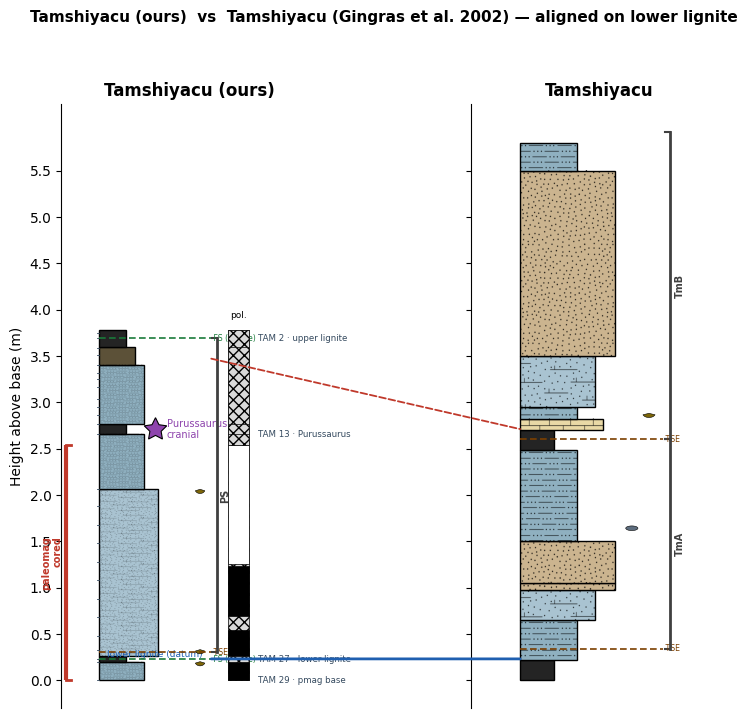

In [12]:
from matplotlib.patches import ConnectionPatch
LIG={"TAM_ours":0.23,"GT":0.71,"SC_ours":0.55,"GSJ":3.175}  # lower-lignite mid-heights (m)

def compare_pair(oB,oS,oM,oN,site,gB,gM,gN,lig_our,lig_ging,extra=None,save=None):
    off=lig_our-lig_ging
    g2=gB.copy(); g2["base_m"]+=off; g2["top_m"]+=off
    m2=dict(gM);
    for k in ("molluscs","concretions"): m2[k]=[h+off for h in gM.get(k,[])]
    m2["surfaces"]=[(h+off,l) for h,l in gM.get("surfaces",[])]
    m2["parasequences"]=[(a+off,b+off,l) for a,b,l in gM.get("parasequences",[])]
    ymax=max(oB.top_m.max(),g2.top_m.max())+0.3; ymin=min(0,g2.base_m.min())-0.3
    fig,ax=plt.subplots(1,2,figsize=(8.6,1.0+(ymax-ymin)*1.05),sharey=True,gridspec_kw=dict(wspace=0.6))
    plot_column(oB,oS,oM,oN,ax=ax[0],polarity=True,site=site)
    plot_column(g2,_empty,m2,gN,ax=ax[1],sample_ticks=False)
    for a in ax: a.set_ylim(ymin,ymax)
    ax[1].set_ylabel("")
    # flat tie at the lower lignite (blue)
    con=ConnectionPatch((1.0,lig_our),(0.0,lig_our),"data","data",axesA=ax[0],axesB=ax[1],
                        color="#1f5fb0",lw=2.0,zorder=10); fig.add_artist(con)
    ax[0].text(0.5,lig_our,"lower lignite (datum)",fontsize=6.5,color="#1f5fb0",va="bottom",ha="center")
    if extra:
        oh,gh=extra; con2=ConnectionPatch((1.0,oh),(0.0,gh+off),"data","data",axesA=ax[0],axesB=ax[1],
                        color="#c0392b",lw=1.3,ls="--",zorder=10); fig.add_artist(con2)
    fig.suptitle(f"{oN}  vs  {gN} (Gingras et al. 2002) — aligned on lower lignite",fontsize=11,weight="bold",y=1.0)
    if save: fig.savefig(save+".png",dpi=220,bbox_inches="tight"); fig.savefig(save+".svg",bbox_inches="tight")
    return fig

compare_pair(TAM_BEDS,TAM_SAMP,MARKERS["TAM"],"Tamshiyacu (ours)","TAM",
             GT_BEDS,GT_MK,"Tamshiyacu",LIG["TAM_ours"],LIG["GT"],
             extra=(3.97-0.5,3.19), save=os.path.join(OUT,"fig_compare_TAM"))
print("saved fig_compare_TAM.png/.svg")

saved fig_compare_SC.png/.svg


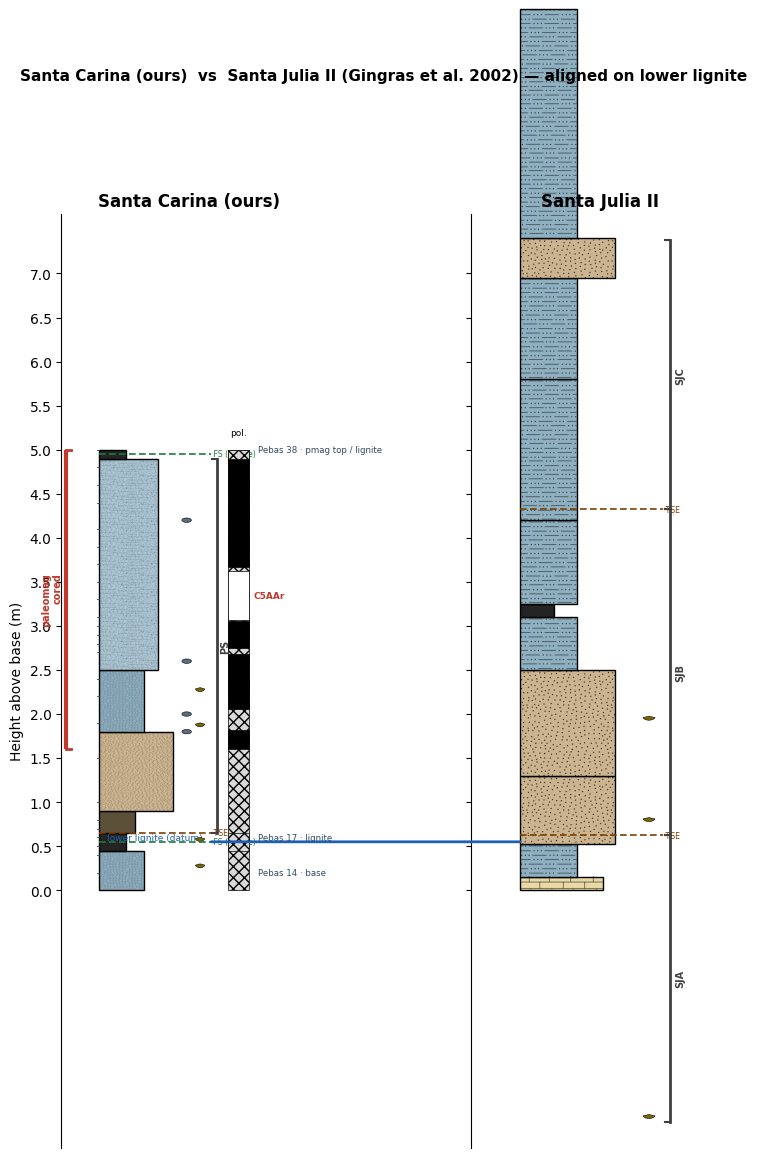

In [13]:
compare_pair(SC_BEDS,SC_SAMP,MARKERS["SC"],"Santa Carina (ours)","SC",
             GSJ_BEDS,GSJ_MK,"Santa Julia II",LIG["SC_ours"],LIG["GSJ"],
             save=os.path.join(OUT,"fig_compare_SC"))
print("saved fig_compare_SC.png/.svg")

## 10 · Export parsed tables

In [14]:
TAM_SAMP.to_csv("parsed_samples_TAM.csv",index=False)
SC_SAMP.to_csv("parsed_samples_SC.csv",index=False)
TAM_BEDS.to_csv("beds_TAM.csv",index=False)
SC_BEDS.to_csv("beds_SC.csv",index=False)
print("wrote parsed_samples_{TAM,SC}.csv and beds_{TAM,SC}.csv")

wrote parsed_samples_{TAM,SC}.csv and beds_{TAM,SC}.csv
